# Experiment 1: Implement Perceptron Algorithm using Scikit-learn

**Aim:** To implement and evaluate a simple Perceptron classifier on the Iris dataset using Scikit-learn.

**Dataset:** Iris dataset (built into scikit-learn) - 150 samples, 3 species, 4 features.
For binary classification we use only two classes (Setosa vs Versicolor) and two features (sepal length, petal length).

In [1]:
# Step 1: Import necessary libraries
from sklearn.datasets import load_iris
from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np
import os
os.makedirs("output", exist_ok=True)   # all plots are saved in this folder

In [2]:
# Step 2: Load dataset and filter for binary classification (Setosa vs Versicolor)
iris = load_iris()
X = iris.data[:, [0, 2]]  # sepal length and petal length
y = iris.target

# Convert to binary classification problem (only class 0 and 1)
X = X[y != 2]
y = y[y != 2]

print("Feature matrix shape:", X.shape)
print("Classes used:", list(iris.target_names[:2]))
print("Samples per class:", np.bincount(y))

Feature matrix shape: (100, 2)
Classes used: ['setosa', 'versicolor']
Samples per class: [50 50]


In [3]:
# Step 3: Train-test split and feature scaling
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)
sc = StandardScaler()
X_train_std = sc.fit_transform(X_train)
X_test_std = sc.transform(X_test)

print("Training samples:", X_train_std.shape[0])
print("Testing samples :", X_test_std.shape[0])

Training samples: 70
Testing samples : 30


In [4]:
# Step 4: Train Perceptron model
ppn = Perceptron(max_iter=40, eta0=0.1, random_state=1)
ppn.fit(X_train_std, y_train)

print("Weights:", ppn.coef_)
print("Bias   :", ppn.intercept_)
print("Epochs run:", ppn.n_iter_)

Weights: [[-0.00803205  0.19536002]]
Bias   : [0.1]
Epochs run: 6


In [5]:
# Step 5: Predict and evaluate
y_pred = ppn.predict(X_test_std)
print("Misclassified test samples:", (y_test != y_pred).sum())
print(f'Accuracy: {accuracy_score(y_test, y_pred):.2f}')

Misclassified test samples: 0
Accuracy: 1.00


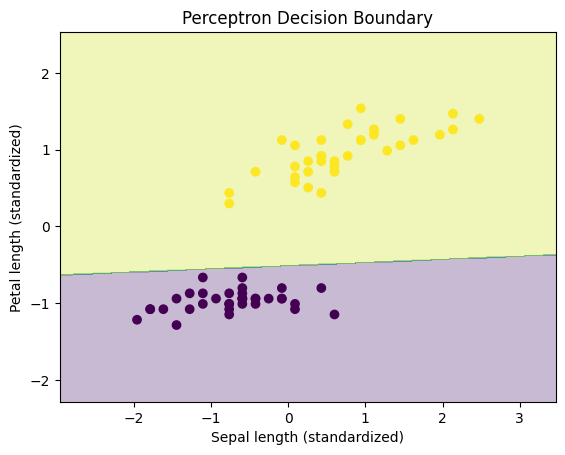

In [6]:
# Step 6: Visualize decision boundary (training data)
x_min, x_max = X_train_std[:, 0].min() - 1, X_train_std[:, 0].max() + 1
y_min, y_max = X_train_std[:, 1].min() - 1, X_train_std[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))
Z = ppn.predict(np.array([xx.ravel(), yy.ravel()]).T)
Z = Z.reshape(xx.shape)
plt.contourf(xx, yy, Z, alpha=0.3)
plt.scatter(X_train_std[:, 0], X_train_std[:, 1], c=y_train, marker='o')
plt.title('Perceptron Decision Boundary')
plt.xlabel('Sepal length (standardized)')
plt.ylabel('Petal length (standardized)')
plt.savefig("output/Exp1_decision_boundary_train.png", dpi=150, bbox_inches="tight")
plt.show()

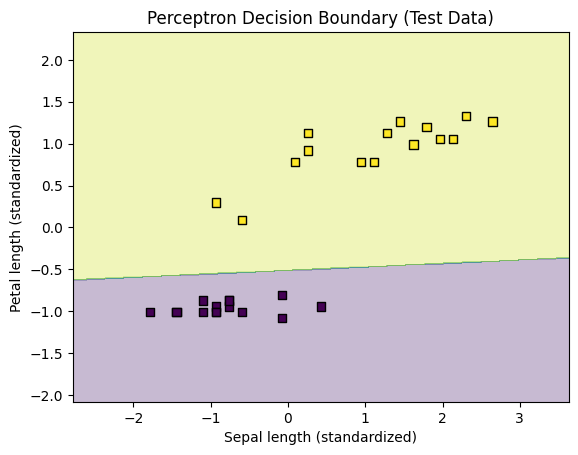

In [7]:
# Step 6b: Visualize decision boundary for test data
x_min, x_max = X_test_std[:, 0].min() - 1, X_test_std[:, 0].max() + 1
y_min, y_max = X_test_std[:, 1].min() - 1, X_test_std[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))
Z = ppn.predict(np.array([xx.ravel(), yy.ravel()]).T)
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3)
plt.scatter(X_test_std[:, 0], X_test_std[:, 1], c=y_test, marker='s', edgecolor='k')
plt.title('Perceptron Decision Boundary (Test Data)')
plt.xlabel('Sepal length (standardized)')
plt.ylabel('Petal length (standardized)')
plt.savefig("output/Exp1_decision_boundary_test.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusion
The Perceptron classifier was successfully implemented and achieved good accuracy on a linearly separable subset of the Iris dataset.